In [54]:
# %% Cellule 0 : installation
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "open_clip_torch", "ipywidgets"], check=False)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'open_clip_torch', 'ipywidgets'], returncode=0)

In [55]:
# %% Cellule 1 : imports et reglages
import os, glob, json, random, itertools, tarfile
from collections import Counter
import numpy as np, requests, torch, torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt
import open_clip

dev = "cuda" if torch.cuda.is_available() else "cpu"
random.seed(0); np.random.seed(0); torch.manual_seed(0)

WARDROBE_DIR = "/kaggle/working/wardrobe"   # <- dossier de TES photos (jpg/png). S'il est vide : garde-robe de demo (cellule 2)
WARDROBE_MAX = 400                          # nombre max de photos lues

In [56]:
# %% Cellule 2 (OPTIONNELLE) : garde-robe de DEMONSTRATION = articles Mytheresa, FILTREE par genre
# A sauter si WARDROBE_DIR contient deja tes propres photos.
GENDER_WANTED = "women"                     # "women" ou "men"  (boys / girls = enfants : toujours ignores)
TARS = ["mytheresa/images-00017.tar.gz"]    # fichiers d'images a lire. Si tu obtiens trop peu de pieces, ajoute d'autres fichiers du dossier mytheresa/ du dataset
WARDROBE_DIR = f"/kaggle/working/wardrobe_{GENDER_WANTED}"   # un dossier PAR genre (evite de melanger les photos entre deux essais)
DESC = {}                                   # descriptions (servent seulement a l'indicateur de la cellule 9)
os.makedirs(WARDROBE_DIR, exist_ok=True)
if not glob.glob(f"{WARDROBE_DIR}/*.jpg"):
    from kaggle_secrets import UserSecretsClient
    from huggingface_hub import login, hf_hub_download
    login(UserSecretsClient().get_secret("hf_syrine"))
    REPO = "ArtmeScienceLab/Garments2Look"
    data = json.load(open(hf_hub_download(REPO, "mytheresa_outfit_v1.0_2512.json", repo_type="dataset")))
    GENDER = {}                             # id de la piece -> genre de l'outfit
    for o in data.values():
        g = str(o.get("gender", "N/A")).lower()
        for c, d in o["outfit"].items():
            GENDER[c] = g; DESC.setdefault(c, d)
    del data
    n = seen = 0
    for tar_file in TARS:
        tar_path = hf_hub_download(REPO, tar_file, repo_type="dataset", local_dir="/kaggle/working/g2l_dl")
        with tarfile.open(tar_path, "r:gz") as tar:
            for m in tar:
                parts = m.name.split("/")
                if m.isfile() and len(parts) == 4 and parts[3] == parts[2] + ".jpg":
                    seen += 1
                    if GENDER.get(parts[2]) != GENDER_WANTED:       # on ne garde QUE le genre voulu
                        continue
                    im = Image.open(tar.extractfile(m)).convert("RGB"); im.thumbnail((448, 448))
                    im.save(f"{WARDROBE_DIR}/{parts[2]}.jpg", quality=90); n += 1
                    if n >= WARDROBE_MAX:
                        break
        os.remove(tar_path)
        if n >= WARDROBE_MAX:
            break
    print(f"{seen} images lues, {n} gardees (genre = {GENDER_WANTED})")
    if n < 150:
        print("ATTENTION : peu de pieces pour ce genre -> ajoute d'autres fichiers dans TARS, sinon les tenues seront pauvres / vides.")
print(len(glob.glob(f"{WARDROBE_DIR}/*.jpg")), "photos dans la garde-robe |", len(DESC), "descriptions")

173 photos dans la garde-robe | 0 descriptions


In [57]:
# %% Cellule 3 : CLIP (pre-entraine, GELE : on ne l'entraine pas, on l'utilise comme un outil)
clip_model, _, preprocess = open_clip.create_model_and_transforms("ViT-B-32", pretrained="laion2b_s34b_b79k")
clip_model = clip_model.to(dev).eval()
tokenizer = open_clip.get_tokenizer("ViT-B-32")

@torch.no_grad()
def encode_texts(texts):                    # texte -> vecteur de 512 nombres
    return F.normalize(clip_model.encode_text(tokenizer(texts).to(dev)).float(), dim=-1).cpu()

@torch.no_grad()
def encode_images(paths, bs=64):            # photo -> vecteur de 512 nombres (meme espace que les textes)
    out = []
    for i in range(0, len(paths), bs):
        x = torch.stack([preprocess(Image.open(p).convert("RGB")) for p in paths[i:i + bs]]).to(dev)
        out.append(F.normalize(clip_model.encode_image(x).float(), dim=-1).cpu())
    return torch.cat(out)

garde-robe : {'bottom': 23, 'dress': 24, 'top': 19, 'shoes': 38, 'bag': 21, 'outer': 31, 'accessory': 4}
pieces ecartees (bonnets/chapeaux, accessoires enfant) : {'hat': 4, 'kids': 9}


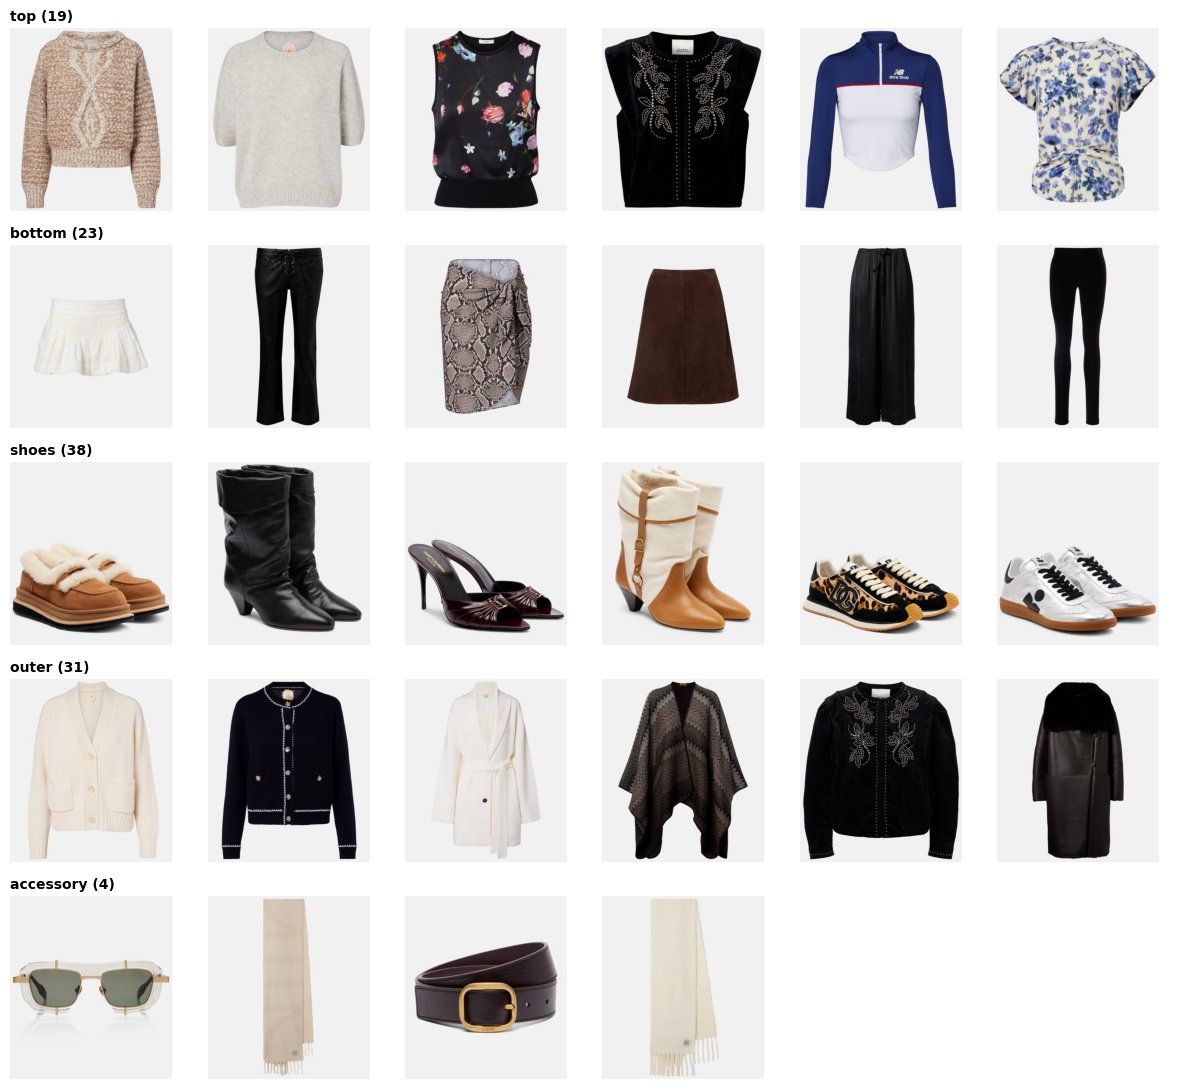

In [58]:
# %% Cellule 4 : la garde-robe : vecteur CLIP de chaque photo + type de piece (haut, bas, chaussures, accessoire...)
paths = sorted(glob.glob(f"{WARDROBE_DIR}/*.jpg") + glob.glob(f"{WARDROBE_DIR}/*.jpeg") + glob.glob(f"{WARDROBE_DIR}/*.png"))
random.shuffle(paths); paths = paths[:WARDROBE_MAX]
emb = encode_images(paths)

SLOTS = ["top", "bottom", "shoes", "outer", "dress", "bag", "accessory"]     # pieces utilisables dans une tenue
EXCLUDED = ["hat", "kids"]                                                   # reconnues par CLIP puis ECARTEES (bonnets / chapeaux, accessoires enfant)
SLOT_TEXT = {
    "top": ["a photo of a top", "a photo of a shirt", "a photo of a blouse", "a photo of a sweater", "a photo of a t-shirt"],
    "bottom": ["a photo of trousers", "a photo of jeans", "a photo of a skirt", "a photo of shorts"],
    "shoes": ["a photo of shoes", "a photo of boots", "a photo of sandals", "a photo of sneakers"],
    "outer": ["a photo of a coat", "a photo of a jacket", "a photo of a blazer"],
    "dress": ["a photo of a dress"],
    "bag": ["a photo of a handbag"],
    "accessory": ["a photo of a scarf", "a photo of sunglasses", "a photo of a belt", "a photo of jewelry",
                  "a photo of a necklace", "a photo of gloves", "a photo of an umbrella", "a photo of a wrist watch"],
    "hat": ["a photo of a beanie", "a photo of a knit winter hat", "a photo of a baseball cap", "a photo of a hat"],
    "kids": ["a photo of a children's accessory", "a photo of a baby accessory", "a photo of a kids hair clip", "a photo of a toy"]}
CLASSES = SLOTS + EXCLUDED
slot_vec = torch.stack([F.normalize(encode_texts(SLOT_TEXT[s]).mean(0), dim=0) for s in CLASSES])
SLOT = [CLASSES[j] for j in (emb @ slot_vec.T).argmax(1).tolist()]       # type devine par CLIP (zero-shot)
for i, p in enumerate(paths):                                          # tes propres photos : un prefixe de nom donne le type (top_blanc.jpg, accessory_echarpe.jpg)
    pre = os.path.basename(p).split("_")[0].lower()
    if pre in CLASSES:
        SLOT[i] = pre                                                  # (hat_xxx.jpg ou kids_xxx.jpg => la photo est ignoree)
print("garde-robe :", dict(Counter(s for s in SLOT if s in SLOTS)))
print("pieces ecartees (bonnets/chapeaux, accessoires enfant) :", dict(Counter(s for s in SLOT if s in EXCLUDED)) or "aucune")

SHOW = ["top", "bottom", "shoes", "outer", "accessory"]
fig, axs = plt.subplots(len(SHOW), 6, figsize=(12, 2.2 * len(SHOW)), squeeze=False)
for r, s in enumerate(SHOW):
    ids = [i for i, x in enumerate(SLOT) if x == s]; random.shuffle(ids)
    for c in range(6):
        axs[r][c].axis("off")
        if c < len(ids):
            axs[r][c].imshow(Image.open(paths[ids[c]]))
    axs[r][0].set_title(s + f" ({len([x for x in SLOT if x == s])})", fontsize=10, weight="bold", loc="left")
plt.tight_layout(); plt.show()

In [59]:
# %% Cellule 5 : METEO REELLE (Open-Meteo : gratuite, sans cle) + choix du lieu
UA = {"User-Agent": "outfit-of-the-day/1.0"}

def wmo(code):                              # code meteo OMM -> (type, libelle anglais)
    if code in (0, 1): return "clear", "clear sky"
    if code in (2, 3): return "cloudy", "cloudy"
    if code in (45, 48): return "fog", "foggy"
    if 51 <= code <= 67 or 80 <= code <= 82: return "rain", "rainy"
    if 71 <= code <= 77 or code in (85, 86): return "snow", "snowy"
    if code >= 95: return "storm", "stormy"
    return "cloudy", "cloudy"

def geocode(name):                          # nom de ville -> coordonnees
    r = requests.get("https://geocoding-api.open-meteo.com/v1/search", headers=UA, timeout=10,
                     params=dict(name=name, count=1, language="en", format="json")).json()
    if not r.get("results"):
        raise ValueError(f"lieu introuvable : {name}")
    g = r["results"][0]
    return dict(place=f"{g['name']}, {g.get('country', '')}".strip(", "), lat=g["latitude"], lon=g["longitude"])

def fetch_weather(loc):                     # coordonnees -> meteo du jour
    r = requests.get("https://api.open-meteo.com/v1/forecast", headers=UA, timeout=10,
                     params=dict(latitude=loc["lat"], longitude=loc["lon"], timezone="auto", forecast_days=1,
                                 current="temperature_2m,apparent_temperature,weather_code,wind_speed_10m",
                                 daily="temperature_2m_max,temperature_2m_min,precipitation_probability_max")).json()
    c, d = r["current"], r.get("daily", {})
    first = lambda k: (d.get(k) or [None])[0]
    kind, label = wmo(int(c["weather_code"]))
    pp = first("precipitation_probability_max")
    return dict(place=loc["place"], temp=c["temperature_2m"], feels=c["apparent_temperature"], wind=c["wind_speed_10m"],
                kind=kind, label=label, tmin=first("temperature_2m_min"), tmax=first("temperature_2m_max"),
                rain_prob=pp if pp is not None else 0)

def detect_location():
    """Position approximative d'apres l'adresse IP.
    ATTENTION : dans Kaggle / Colab, l'IP est celle du SERVEUR, pas la tienne. Sur ton PC, ca marche."""
    for url, parse in (("https://ipapi.co/json/", lambda j: (j["city"], j["country_name"], j["latitude"], j["longitude"])),
                       ("https://ipinfo.io/json", lambda j: (j["city"], j["country"], *j["loc"].split(",")))):
        try:
            c, k, la, lo = parse(requests.get(url, headers=UA, timeout=6).json())
            return dict(place=f"{c}, {k}", lat=float(la), lon=float(lo))
        except Exception:
            continue
    return None

MANUAL_LABEL = {"clear": "clear sky", "cloudy": "cloudy", "rain": "rainy", "snow": "snowy", "storm": "stormy", "fog": "foggy"}
def manual_weather(temp, kind="clear", wind=10.0):      # meteo choisie a la main
    return dict(place="meteo manuelle", temp=temp, feels=temp, wind=wind, kind=kind, label=MANUAL_LABEL[kind],
                tmin=None, tmax=None, rain_prob=100 if kind in ("rain", "storm") else 0)

COUNTRIES = {"Tunisie": "Tunis", "France": "Paris", "Maroc": "Rabat", "Algerie": "Algiers", "Egypte": "Cairo",
             "Espagne": "Madrid", "Italie": "Rome", "Allemagne": "Berlin", "Royaume-Uni": "London", "Canada": "Ottawa",
             "Etats-Unis": "New York", "Arabie saoudite": "Riyadh", "Emirats arabes unis": "Abu Dhabi", "Qatar": "Doha",
             "Turquie": "Ankara", "Japon": "Tokyo", "Chine": "Beijing", "Russie": "Moscow", "Bresil": "Brasilia",
             "Inde": "New Delhi", "Suede": "Stockholm", "Norvege": "Oslo", "Islande": "Reykjavik", "Australie": "Canberra",
             "Senegal": "Dakar"}                  # pays -> ville de reference (ajoute les tiens)

In [65]:
# %% Cellule 6 : METEO + OCCASION + GENRE -> TEXTE -> CLIP compare ce texte aux photos de la garde-robe
BANDS = [(-99, 5, "freezing"), (5, 12, "cold"), (12, 18, "cool"), (18, 25, "mild"), (25, 99, "hot")]
band_of = lambda t: next(n for lo, hi, n in BANDS if lo <= t < hi)         # on se base sur la temperature RESSENTIE

GENDERS = ("women", "men", "unisex")       # "unisex" = tenues sans robe / jupe / talons (memes regles que "men")
DEFAULT_GENDER = "women"                   # dans l'app : passer le genre du profil utilisateur (gender=...)

# Ce que l'on porte selon la tranche de temperature (les phrases sont lues par CLIP, donc en anglais)
PROMPTS = {   # version FEMME (reference)
    "top": {"freezing": ["a thick warm wool sweater", "a heavy knit turtleneck"],
            "cold": ["a warm knit sweater", "a long sleeve warm top", "a cardigan"],
            "cool": ["a long sleeve shirt", "a light sweater"],
            "mild": ["a light blouse", "a short sleeve top", "a cotton shirt"],
            "hot": ["a light sleeveless top", "a thin short sleeve t-shirt", "a linen shirt"]},
    "bottom": {"freezing": ["thick warm wool trousers", "warm lined pants"],
               "cold": ["long trousers", "jeans"],
               "cool": ["jeans", "trousers"],
               "mild": ["light trousers", "a midi skirt"],
               "hot": ["shorts", "a short light skirt", "light linen trousers"]},
    "dress": {"freezing": ["a thick knit sweater dress", "a long sleeve wool dress"],
              "cold": ["a long sleeve knit dress", "a long sleeve midi dress"],
              "cool": ["a long sleeve dress"],
              "mild": ["a light midi dress"],
              "hot": ["a light sleeveless summer dress", "a linen dress"]},
    "shoes": {"freezing": ["warm winter boots"],
              "cold": ["ankle boots", "leather boots"],
              "cool": ["sneakers", "loafers"],
              "mild": ["sneakers", "flat shoes"],
              "hot": ["sandals", "open toe slides"]},
    "outer": {"freezing": ["a heavy winter coat", "a puffer jacket"],
              "cold": ["a warm coat", "a wool coat"],
              "cool": ["a light jacket", "a blazer"],
              "mild": ["a thin light jacket"],
              "hot": ["a thin light jacket"]},
    # accessoire : seulement si le temps ou l'occasion le demande (liste vide = pas d'accessoire). Jamais de bonnet / chapeau.
    "accessory": {"freezing": ["a thick warm scarf", "warm gloves"],
                  "cold": ["a warm scarf", "gloves"],
                  "cool": ["a light scarf"],
                  "mild": [],
                  "hot": ["sunglasses"]}}
PROMPTS_MEN = {**PROMPTS,                  # version HOMME / UNISEXE : pas de jupe, pas de robe, pas de "blouse"
    "top": {"freezing": ["a thick warm wool sweater", "a heavy knit turtleneck"],
            "cold": ["a warm knit sweater", "a long sleeve warm top", "a cardigan"],
            "cool": ["a long sleeve shirt", "a light sweater"],
            "mild": ["a polo shirt", "a short sleeve shirt", "a cotton shirt"],
            "hot": ["a thin short sleeve t-shirt", "a linen shirt", "a light polo shirt"]},
    "bottom": {"freezing": ["thick warm wool trousers", "warm lined pants"],
               "cold": ["long trousers", "jeans"],
               "cool": ["jeans", "chino trousers"],
               "mild": ["light chino trousers", "light trousers"],
               "hot": ["shorts", "light linen trousers"]},
    "dress": {}}
PROMPTS_BY_GENDER = {"women": PROMPTS, "men": PROMPTS_MEN, "unisex": PROMPTS_MEN}

EXTRA = {("outer", "rain"): ["a waterproof raincoat", "a trench coat"], ("shoes", "rain"): ["waterproof rain boots"],
         ("outer", "snow"): ["a thick puffer coat"], ("shoes", "snow"): ["snow boots"],
         ("outer", "wind"): ["a windbreaker jacket"],
         ("accessory", "rain"): ["an umbrella"], ("accessory", "snow"): ["warm gloves", "a thick scarf"],
         ("accessory", "sun"): ["sunglasses"]}

# ---- OCCASIONS : chaque occasion ajoute un groupe de phrases par type de piece (en plus de la meteo) ----
# Chaque occasion a une config "women" et une config "men" (unisex utilise "men"). Cles possibles dans une config :
#   "dress"      : None = pas de robe | un nombre = bonus donne a la formule "robe" face a "haut + bas"
#   "only_dress" : True = TOUJOURS une robe (jamais haut + bas), sauf si la garde-robe n'a aucune robe
#   "shoe_rule"  : regle OBLIGATOIRE sur les chaussures (voir SHOE_RULES plus bas)
#   "need_outer" : True = veste / blazer TOUJOURS ajoute, meme par beau temps (tailleur, costume)
#   "prompts"    : phrases par type de piece
OCCASIONS = {
    "casual": dict(label="Casual / quotidien",
        women=dict(dress=0.0,
            prompts={"top": ["a casual t-shirt", "a relaxed sweatshirt", "a casual knit top"],
                     "bottom": ["relaxed jeans", "casual chino pants"],
                     "dress": ["a casual day dress"],
                     "shoes": ["white sneakers", "casual flat shoes"],
                     "outer": ["a casual denim jacket", "a bomber jacket"]}),
        men=dict(
            prompts={"top": ["a casual t-shirt", "a relaxed sweatshirt", "a casual polo shirt"],
                     "bottom": ["relaxed jeans", "casual chino pants"],
                     "shoes": ["white sneakers", "casual sneakers"],
                     "outer": ["a casual denim jacket", "a bomber jacket"]})),
    "meeting": dict(label="Meeting / travail (tailleur / costume)",
        women=dict(need_outer=True, shoe_rule="heels_or_sneakers",
            prompts={"top": ["a button-up shirt", "a silk blouse", "a fine knit top"],
                     "bottom": ["matching suit trousers", "a tailored suit skirt"],
                     "shoes": ["elegant high heels", "heeled ankle boots", "clean white sneakers"],
                     "outer": ["a tailored suit blazer", "a suit jacket"],
                     "accessory": ["a leather belt", "a wrist watch"]}),
        men=dict(need_outer=True, shoe_rule="dress_or_sneakers",
            prompts={"top": ["a button-up shirt", "a fine knit sweater"],
                     "bottom": ["matching suit trousers"],
                     "shoes": ["leather oxford shoes", "leather derby shoes", "clean white sneakers"],
                     "outer": ["a tailored suit jacket", "a suit blazer"],
                     "accessory": ["a leather belt", "a wrist watch", "a silk tie"]})),
    "fancy": dict(label="Fancy / soiree",
        women=dict(dress=0.0, only_dress=True, shoe_rule="heels",
            prompts={"top": ["an elegant satin blouse", "a sequin top", "a silk top"],
                     "bottom": ["elegant wide leg trousers", "a satin skirt"],
                     "dress": ["an elegant evening dress", "a cocktail dress"],
                     "shoes": ["elegant high heels", "heeled ankle boots", "stiletto pumps"],
                     "outer": ["an elegant evening coat", "a tuxedo blazer"],
                     "accessory": ["elegant jewelry", "a statement necklace"]}),
        men=dict(need_outer=True, shoe_rule="dress_shoes",
            prompts={"top": ["a white formal dress shirt", "a dress shirt"],
                     "bottom": ["matching suit trousers", "formal dress trousers"],
                     "shoes": ["black leather oxford shoes", "polished dress shoes"],
                     "outer": ["a tuxedo jacket", "a formal suit jacket"],
                     "accessory": ["a bow tie", "a silk tie", "a wrist watch"]})),
    "date": dict(label="Date / sortie",
        women=dict(dress=0.0, only_dress=True, shoe_rule="heels",
            prompts={"top": ["a stylish fitted top", "a silk blouse"],
                     "bottom": ["a stylish skirt", "dark jeans"],
                     "dress": ["a chic dress"],
                     "shoes": ["heeled ankle boots", "heeled sandals", "stylish high heels"],
                     "outer": ["a stylish leather jacket", "a chic blazer"],
                     "accessory": ["delicate jewelry", "a necklace"]}),
        men=dict(shoe_rule="dress_or_sneakers",
            prompts={"top": ["a fitted shirt", "a fine knit sweater", "a polo shirt"],
                     "bottom": ["dark jeans", "chino trousers"],
                     "shoes": ["chelsea boots", "leather loafers", "clean minimalist sneakers"],
                     "outer": ["a stylish leather jacket", "a casual blazer"],
                     "accessory": ["a wrist watch", "a leather belt"]}))}

def occ_cfg(occasion, gender):
    """Config complete d'une occasion pour un genre donne (valeurs par defaut : pas de robe, pas de regle)."""
    cfg = dict(label=OCCASIONS[occasion]["label"], dress=None, only_dress=False, shoe_rule=None, need_outer=False, prompts={})
    cfg.update(OCCASIONS[occasion]["women" if gender == "women" else "men"])
    return cfg

COND_W = 1.5      # poids d'une condition (pluie, neige, vent) face a la tranche de temperature (poids 1) : la protection prime un peu
ACC_MIN = 0.20    # similarite CLIP minimale pour qu'une photo compte comme accessoire pertinent (sinon : pas d'accessoire). A ajuster.
OCC_W = 2.0       # poids de l'occasion (1 = autant que la temperature ; monte-le pour que l'occasion prime sur le confort)
CONTRAST = 0.5    # 0 = note brute | 1 = on retire ce que la photo a de commun avec les AUTRES occasions (specifique a celle-ci). Monte-le si les occasions se ressemblent encore
# ---- REGLES CHAUSSURES (filtre OBLIGATOIRE : une chaussure est gardee si sa meilleure similarite CLIP "autorise" > sa meilleure similarite "interdit") ----
HEEL_POS = ["high heel shoes", "stiletto pumps", "heeled ankle boots", "heeled sandals", "block heel boots"]
SNEAKER_POS = ["sneakers", "clean white sneakers", "minimalist leather sneakers"]
DRESS_SHOE_POS = ["leather oxford shoes", "derby shoes", "polished dress shoes", "leather loafers", "chelsea boots"]
FLAT_NEG = ["flat shoes", "flat sandals", "flat boots", "loafers"]
CLOG_NEG = ["clogs", "shearling lined clogs", "fur slippers", "mules", "slides", "flip flops"]      # sabots, mules, chaussons : jamais
SHOE_RULES = {"heels": dict(allow=HEEL_POS, ban=FLAT_NEG + CLOG_NEG + ["sneakers"]),                # femme : fancy, date
              "heels_or_sneakers": dict(allow=HEEL_POS + SNEAKER_POS, ban=FLAT_NEG + CLOG_NEG),     # femme : meeting
              "dress_shoes": dict(allow=DRESS_SHOE_POS, ban=CLOG_NEG + ["sneakers", "sports running shoes"]),   # homme : fancy
              "dress_or_sneakers": dict(allow=DRESS_SHOE_POS + SNEAKER_POS, ban=CLOG_NEG + ["sports running shoes"])}  # homme : meeting, date
SHOE_MARGIN = 0.0   # marge de securite : monte-la (ex. 0.02) pour etre plus strict, baisse-la si trop de chaussures sont refusees

def shoe_margin(idx, rule):
    """Pour chaque photo de chaussure : (similarite CLIP 'autorise') - (similarite CLIP 'interdit'). > 0 => chaussure acceptee."""
    r = SHOE_RULES[rule]
    pos = encode_texts([f"a product photo of {x}" for x in r["allow"]]); neg = encode_texts([f"a product photo of {x}" for x in r["ban"]])
    E = emb[idx]
    return (E @ pos.T).numpy().max(1) - (E @ neg.T).numpy().max(1)

is_rain = lambda w: w["kind"] in ("rain", "storm") or (w["rain_prob"] or 0) >= 60
is_snow = lambda w: w["kind"] == "snow"
is_windy = lambda w: (w["wind"] or 0) >= 30                                  # km/h
is_sunny = lambda w: w["kind"] == "clear" and w["feels"] >= 22

def weather_to_text(w, occasion=None, gender=DEFAULT_GENDER):
    t = f"{band_of(w['feels'])} {w['label']} day, feels like {w['feels']:.0f} degrees celsius"
    t += (", windy" if is_windy(w) else "") + (", rain expected" if is_rain(w) and w["kind"] not in ("rain", "storm") else "")
    return t + (f", outfit for: {occ_cfg(occasion, gender)['label']}" if occasion else "")

def slots_needed(w, occasion=None, use_dress=False, gender=DEFAULT_GENDER):
    s = ["dress", "shoes"] if use_dress else ["top", "bottom", "shoes"]
    if w["feels"] < 18 or is_rain(w) or is_snow(w) or is_windy(w) or (occasion and occ_cfg(occasion, gender)["need_outer"]):
        s.append("outer")                                                    # veste / manteau seulement si utile (blazer toujours pour meeting / costume)
    s.append("accessory")                                                    # sera ignore s'il n'y a aucune raison d'en mettre
    return s

def prompt_groups(slot, w, occasion=None, gender=DEFAULT_GENDER, with_occ=True):
    """Liste de (poids, phrases) : temperature + une entree par condition active (pluie, neige, vent, soleil) + occasion."""
    groups = []
    base = PROMPTS_BY_GENDER[gender].get(slot, {}).get(band_of(w["feels"]), [])
    if base:
        groups.append((1.0, base))
    for cond, on in (("rain", is_rain(w)), ("snow", is_snow(w)), ("wind", is_windy(w)), ("sun", is_sunny(w))):
        if on and (slot, cond) in EXTRA:
            groups.append((COND_W, EXTRA[(slot, cond)]))
    if with_occ and occasion and occ_cfg(occasion, gender)["prompts"].get(slot):
        groups.append((OCC_W, occ_cfg(occasion, gender)["prompts"][slot]))
    return [(wt, [f"a product photo of {x}" for x in g]) for wt, g in groups]

def prompts_for(slot, w, occasion=None, gender=DEFAULT_GENDER):      # toutes les phrases envoyees a CLIP (pour les afficher)
    return [p for _, g in prompt_groups(slot, w, occasion, gender) for p in g]

zscore = lambda x: (x - x.mean()) / (x.std() if x.std() > 1e-6 else 1.0)

def occasion_term(s, occasion, gender, idx):
    """(note brute, note CONTRASTEE) de chaque photo pour l'occasion. Contrastee = ressemblance a cette occasion
    moins ressemblance moyenne aux AUTRES occasions : sinon 'robe de soiree' et 'robe chic' donnent la meme gagnante."""
    mine = occ_cfg(occasion, gender)["prompts"].get(s)
    if not mine:
        return None
    vec = lambda ph: F.normalize(encode_texts([f"a product photo of {x}" for x in ph]).mean(0), dim=0)
    plain = (emb[idx] @ vec(mine)).numpy()
    others = [occ_cfg(o, gender)["prompts"].get(s) for o in OCCASIONS if o != occasion]
    others = [vec(p) for p in others if p]
    if not others or CONTRAST == 0:
        return plain, plain
    base = (emb[idx] @ torch.stack(others).mean(0)).numpy()
    return plain, plain - CONTRAST * base

def score_slot(s, w, occasion, gender, topk):
    """Notes CLIP de toutes les photos d'un type de piece -> les topk meilleures [(index_photo, note)]."""
    groups = prompt_groups(s, w, occasion, gender, with_occ=False)         # meteo + conditions (l'occasion est traitee a part, en contraste)
    idx = [i for i, sl in enumerate(SLOT) if sl == s]
    has_occ = bool(occasion and occ_cfg(occasion, gender)["prompts"].get(s))
    if (not groups and not has_occ) or not idx:
        return None
    rule = occ_cfg(occasion, gender)["shoe_rule"] if occasion else None
    if s == "shoes" and rule:                                                # occasion habillee : on ne garde QUE les chaussures autorisees
        sm = shoe_margin(idx, rule)
        ok = [i for i, m in zip(idx, sm) if m > SHOE_MARGIN]
        if ok:
            idx = ok
        else:                                                                # aucune chaussure conforme detectee : on prend les plus proches
            print("(attention : aucune chaussure conforme a la regle de l'occasion, on prend les plus proches)")
            idx = [idx[j] for j in np.argsort(-sm)[:3]]
    z, raw, tot = 0, 0, 0.0                                                # chaque critere (temperature, pluie, occasion...) est note puis additionne
    for wt, g_ in groups:
        t = F.normalize(encode_texts(g_).mean(0), dim=0)
        sim = (emb[idx] @ t).numpy()
        z = z + wt * zscore(sim); raw = raw + wt * sim; tot += wt
    if has_occ:
        plain, contrast = occasion_term(s, occasion, gender, idx)
        z = z + OCC_W * zscore(contrast); raw = raw + OCC_W * plain; tot += OCC_W
    z = zscore(z); raw = raw / tot
    order = [j for j in np.argsort(-z) if s != "accessory" or raw[j] >= ACC_MIN]   # accessoire : on exige une vraie correspondance
    return [(idx[j], float(z[j])) for j in order[:topk]] or None

def best_combo(cand, gamma):
    names = list(cand)
    combos = list(itertools.product(*[cand[s] for s in names]))
    wscore = np.array([sum(z for _, z in c) / len(names) for c in combos])
    coh = []
    for c in combos:
        E = emb[[i for i, _ in c]]; n = len(c)
        coh.append(((E @ E.T).sum().item() - n) / (n * (n - 1)) if n > 1 else 0.0)
    tot = wscore + gamma * zscore(np.array(coh))
    k = int(tot.argmax())
    return {s: i for s, (i, _) in zip(names, combos[k])}, float(tot[k])

def pick_outfit(w, occasion=None, gender=DEFAULT_GENDER, topk=5, gamma=0.5):
    """1) pour chaque type de piece : CLIP note chaque photo selon les phrases de la meteo + de l'occasion (+ du genre)
       2) on garde les topk meilleures de chaque type, puis on choisit la COMBINAISON qui a le meilleur score
          + un petit bonus de coherence de style (les photos se ressemblent / vont ensemble).
       Si l'occasion le permet (femme), on compare aussi la formule 'robe + chaussures' a 'haut + bas + chaussures'.
       L'accessoire (echarpe, lunettes, ceinture, bijou, cravate...) n'est ajoute que si le temps ou l'occasion le justifie.
       gender = 'women' | 'men' | 'unisex' (genre du profil utilisateur)."""
    if gender not in GENDERS:
        raise ValueError(f"genre inconnu : {gender} (choix : {list(GENDERS)})")
    if occasion is not None and occasion not in OCCASIONS:
        raise ValueError(f"occasion inconnue : {occasion} (choix : {list(OCCASIONS)})")
    cfg = occ_cfg(occasion, gender) if occasion else dict(dress=None, only_dress=False)
    dress_bonus, only_dress = cfg["dress"], cfg["only_dress"]
    results = []
    for use_dress in ([True, False] if only_dress else [False] + ([True] if dress_bonus is not None else [])):
        if only_dress and results:
            break                                                          # robe trouvee : on ne regarde pas haut + bas
        cand = {}
        for s in slots_needed(w, occasion, use_dress, gender):
            r = score_slot(s, w, occasion, gender, topk)
            if r:
                cand[s] = r
            elif s in ("top", "bottom", "shoes", "dress") and not (use_dress is False and s == "dress"):
                if use_dress:
                    cand = {}; break                                       # pas de robe dans la garde-robe : formule robe impossible
                print(f"(aucune piece '{s}' dans la garde-robe)")
        if cand:
            pick, sc = best_combo(cand, gamma)
            results.append((sc + ((dress_bonus or 0.0) if use_dress else 0.0), pick))
        elif only_dress and use_dress:
            print("(aucune robe dans la garde-robe : on utilise haut + bas a la place)")
    if not results:
        raise RuntimeError("garde-robe vide ou sans haut/bas/chaussures")
    return max(results, key=lambda r: r[0])[1]

def show_outfit(w, pick, occasion=None, gender=DEFAULT_GENDER):
    fig, axs = plt.subplots(1, len(pick) + 1, figsize=(3.2 * (len(pick) + 1), 4.4))
    rng = f"{w['tmin']:.0f} a {w['tmax']:.0f} C aujourd'hui | " if w.get("tmin") is not None else ""
    occ = f"Occasion : {occ_cfg(occasion, gender)['label']}\n\n" if occasion else ""
    axs[0].axis("off")
    axs[0].text(0, 0.5, f"{w['place']}\n\n{w['temp']:.0f} C (ressenti {w['feels']:.0f} C)\n{rng}vent {w['wind']:.0f} km/h\n"
                        f"pluie probable : {w['rain_prob']:.0f} %\n\n{occ}Texte envoye a CLIP :\n{weather_to_text(w, occasion, gender)}", fontsize=10, va="center", wrap=True)
    for ax, (s, i) in zip(axs[1:], pick.items()):
        ax.imshow(Image.open(paths[i])); ax.axis("off"); ax.set_title(s, weight="bold")
    plt.tight_layout(); plt.show()

def outfit_of_the_day(city=None, country=None, auto=False, manual=None, occasion=None, gender=DEFAULT_GENDER, show=True):
    """manual = dict(temp=8, kind='rain')  |  auto=True : position par IP  |  country='Tunisie'  |  city='Tunis'
       occasion = None | 'casual' | 'meeting' | 'fancy' | 'date'   |   gender = 'women' | 'men' | 'unisex'"""
    if manual:
        w = manual_weather(**manual)
    else:
        if auto:
            loc = detect_location()
            if loc is None:
                raise RuntimeError("position non detectee : donne une ville (city=...)")
        elif country:
            loc = geocode(COUNTRIES.get(country, country))
        else:
            loc = geocode(city or "Tunis")
        w = fetch_weather(loc)
    pick = pick_outfit(w, occasion, gender)
    if show:
        show_outfit(w, pick, occasion, gender)
    return w, pick

In [66]:
# %% Cellule 7 : INTERFACE : ma position (auto) / pays / ville / meteo manuelle + OCCASION + PROFIL (genre)
import ipywidgets as W
from IPython.display import clear_output

mode = W.ToggleButtons(options=["Ville", "Pays", "Ma position (auto)", "Meteo manuelle"], description="Source :")
city = W.Text(value="Tunis", description="Ville :")
country = W.Dropdown(options=sorted(COUNTRIES), value="Tunisie", description="Pays :")
temp = W.IntSlider(value=15, min=-15, max=45, description="Temp (C) :")
kind = W.Dropdown(options=["clear", "cloudy", "rain", "snow", "storm", "fog"], value="clear", description="Ciel :")
windy = W.Checkbox(value=False, description="Vent fort")
occ = W.Dropdown(options=[("Aucune (meteo seule)", None)] + [(o["label"], k) for k, o in OCCASIONS.items()],
                 value="casual", description="Occasion :")
gender = W.Dropdown(options=[("Femme", "women"), ("Homme", "men"), ("Unisexe", "unisex")], value=DEFAULT_GENDER, description="Profil :")
btn = W.Button(description="Generer ma tenue du jour", button_style="primary")
out = W.Output()

def on_click(_):
    with out:
        clear_output(wait=True)
        try:
            m, o, g = mode.value, occ.value, gender.value
            if m == "Ville": outfit_of_the_day(city=city.value, occasion=o, gender=g)
            elif m == "Pays": outfit_of_the_day(country=country.value, occasion=o, gender=g)
            elif m == "Ma position (auto)": outfit_of_the_day(auto=True, occasion=o, gender=g)
            else: outfit_of_the_day(manual=dict(temp=temp.value, kind=kind.value, wind=40.0 if windy.value else 10.0), occasion=o, gender=g)
        except Exception as e:
            print("Erreur :", e)
btn.on_click(on_click)
display(W.VBox([mode, city, country, W.HBox([temp, kind, windy]), occ, gender, btn, out]))

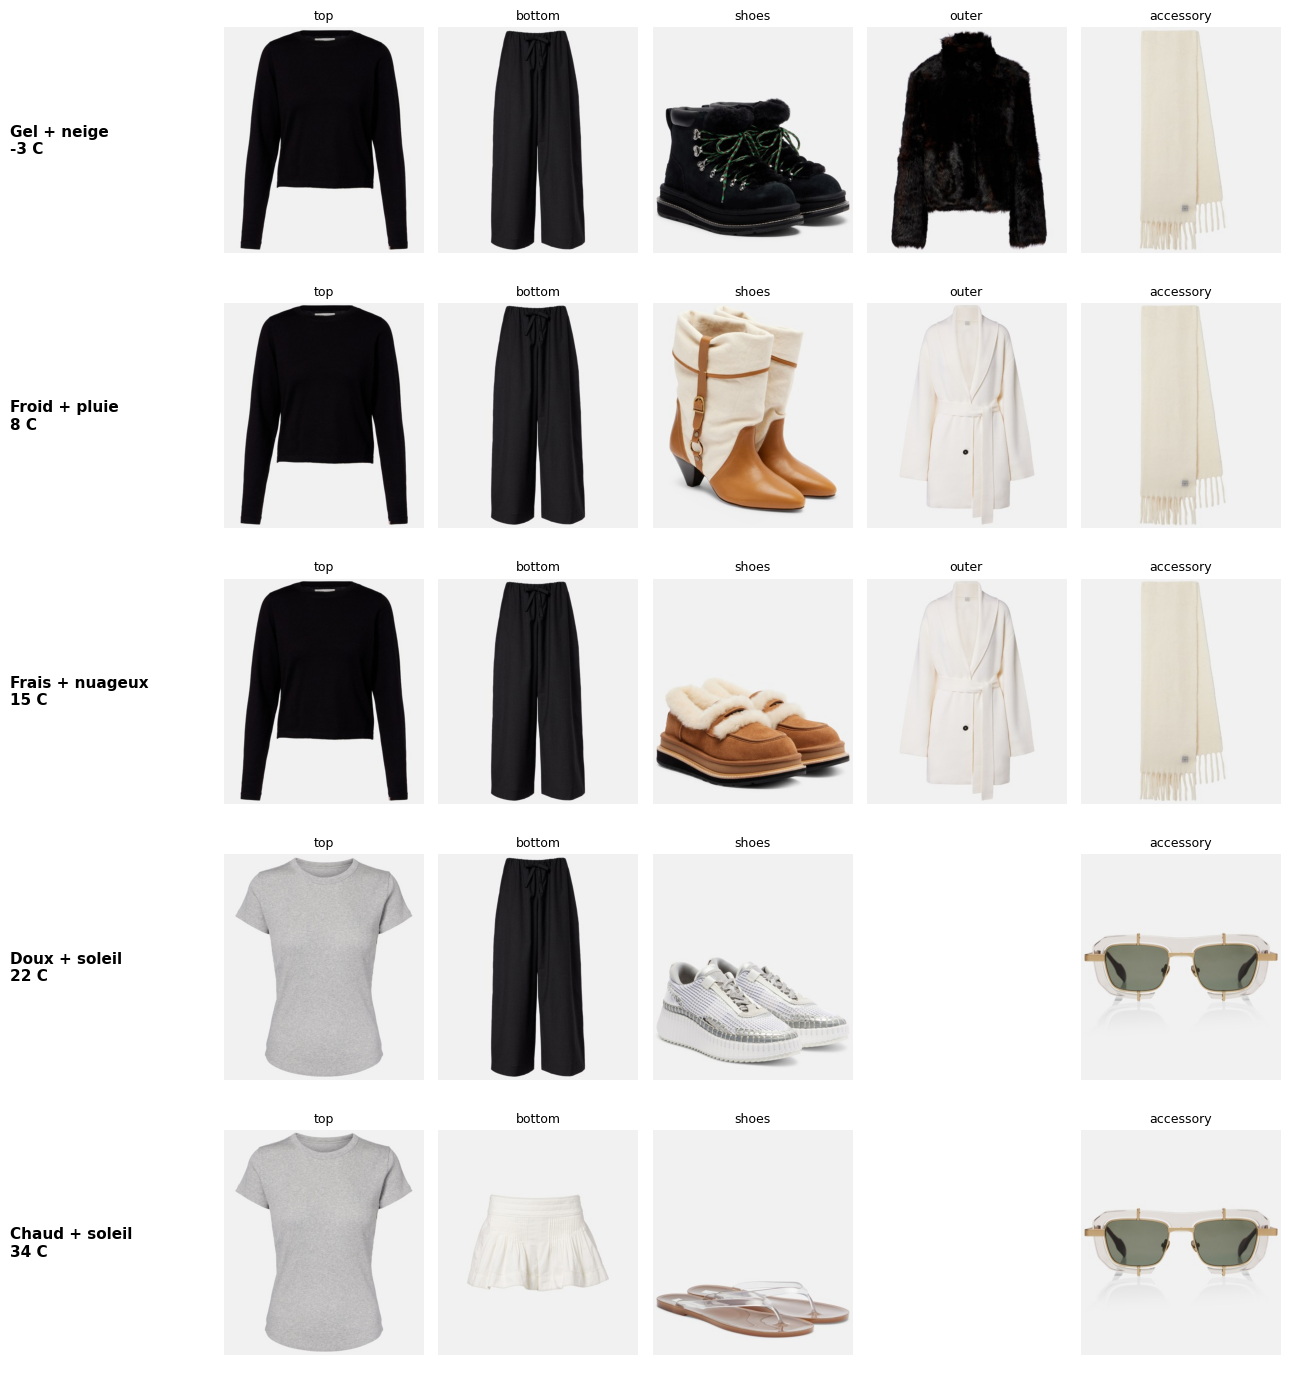

In [62]:
# %% Cellule 8 : RESULTAT : la MEME garde-robe, 5 meteos differentes -> 5 tenues differentes (avec accessoire quand il est utile)
def grid(rows, order, title_w=2.0):
    """rows = [(titre, sous-titre, pick)] -> une ligne par tenue, une colonne par type de piece."""
    fig, axs = plt.subplots(len(rows), len(order) + 1, figsize=(2.2 * len(order) + 2, 2.8 * len(rows)), squeeze=False)
    for r, (name, sub, pick) in enumerate(rows):
        for ax in axs[r]:
            ax.axis("off")
        axs[r][0].text(0, 0.5, f"{name}\n{sub}", fontsize=11, weight="bold", va="center")
        for c, s in enumerate(order):
            if s in pick:
                axs[r][c + 1].imshow(Image.open(paths[pick[s]])); axs[r][c + 1].set_title(s, fontsize=9)
    plt.tight_layout(); plt.show()

DEMO = [("Gel + neige", dict(temp=-3, kind="snow", wind=15.0)), ("Froid + pluie", dict(temp=8, kind="rain")),
        ("Frais + nuageux", dict(temp=15, kind="cloudy")), ("Doux + soleil", dict(temp=22, kind="clear")),
        ("Chaud + soleil", dict(temp=34, kind="clear"))]
ORDER = ["top", "bottom", "shoes", "outer", "accessory"]
demo_picks, rows = {}, []
for name, m in DEMO:
    w = manual_weather(**m); pick = pick_outfit(w); demo_picks[name] = pick
    rows.append((name, f"{m['temp']} C", pick))
grid(rows, ORDER)

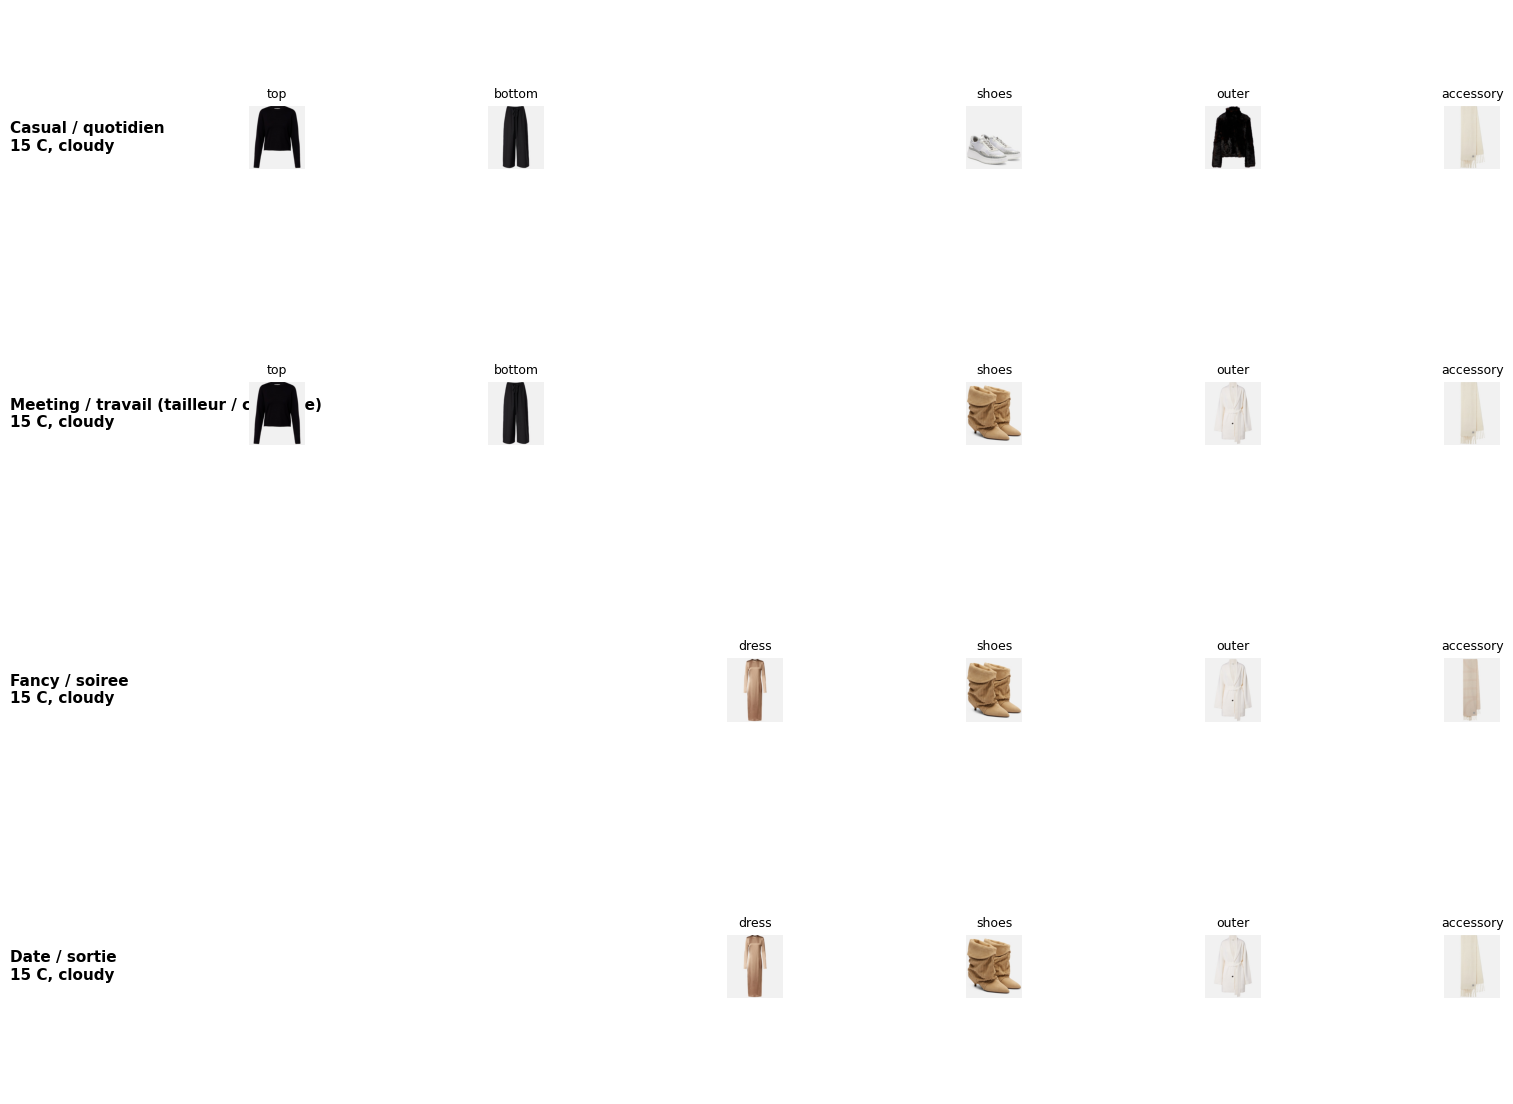

In [63]:
# %% Cellule 8b : RESULTAT : la MEME meteo, plusieurs OCCASIONS -> tenues differentes
METEO_TEST = dict(temp=15, kind="cloudy")            # <- change la meteo pour comparer
w = manual_weather(**METEO_TEST)
ORDER2 = ["top", "bottom", "dress", "shoes", "outer", "accessory"]
rows, occ_picks = [], {}
for key, o in OCCASIONS.items():
    pick = pick_outfit(w, key); occ_picks[key] = pick
    rows.append((o["label"], f"{METEO_TEST['temp']} C, {METEO_TEST['kind']}", pick))
grid(rows, ORDER2)

In [64]:
# %% Cellule 9 : INDICATEUR de pertinence (utilise les descriptions Mytheresa, si disponibles)
# Idee : par temps froid, les pieces choisies doivent plus souvent etre "chaudes" (laine, manteau, bottes...)
# que le taux moyen de la garde-robe ; par temps chaud, plus souvent "legeres" (lin, short, sandales...).
# C'est un indicateur approximatif (recherche de mots-cles dans la description), pas une verite absolue.
WARM = ["wool", "knit", "cashmere", "coat", "puffer", "down", "fleece", "boot", "turtleneck", "sweater", "padded", "shearling", "parka", "jumper", "cardigan", "scarf", "glove"]
LIGHT = ["linen", "cotton", "sleeveless", "tank", "short", "sandal", "mini", "t-shirt", "slide", "halter", "tee", "sunglass"]
name_of = lambda i: os.path.splitext(os.path.basename(paths[i]))[0]
desc_i = lambda i: DESC.get(name_of(i), "").lower()
share = lambda ids, kw: float(np.mean([any(k in desc_i(i) for k in kw) for i in ids])) if ids else float("nan")

if not any(desc_i(i) for i in range(len(paths))):
    print("Pas de descriptions (garde-robe personnelle) : indicateur ignore. Regarde plutot la figure de la cellule 8.")
else:
    allp = [i for i, s in enumerate(SLOT) if s in ("top", "bottom", "shoes", "outer", "accessory")]
    print(f"taux de base dans la garde-robe : chaud {share(allp, WARM):.2f} | leger {share(allp, LIGHT):.2f}\n")
    print(f"{'temperature':>12}{'pieces chaudes':>16}{'pieces legeres':>16}")
    for t in (-5, 0, 5, 10, 15, 20, 25, 30, 35):
        ids = list(pick_outfit(manual_weather(t, "clear")).values())
        print(f"{t:>10} C{share(ids, WARM):>16.2f}{share(ids, LIGHT):>16.2f}")

Pas de descriptions (garde-robe personnelle) : indicateur ignore. Regarde plutot la figure de la cellule 8.
